In [1]:
import anndata as ad


# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/split_spatial_chromium/breast_cancer_chromium_277genes.h5ad')
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated_hardcap.h5ad')
# st_data = ad.read_h5ad('/home/jwinchel/Syndri/data/breast_cancer_rctd_by_sample/GSM9509174_breast_breast_B1_B1_3_rctd.h5ad')
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung9-Rep1_adata_annotated.h5ad')

In [2]:
sc_data = sc_data[sc_data.obs['harmony_spatial_tissue']=='Lung9_Rep1']
# st_data = st_data[st_data.obs['cell_type']!='nan']
st_data.obsm['X_pca_harmony'] = st_data.obsm['X_pca_harmony_Lung9_Rep1']
sc_data,st_data

(View of AnnData object with n_obs × n_vars = 40362 × 957
     obs: 'species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Barcode', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'x_NSCLC_all_cells', 'y_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'x_NSCLC_and_blood_immune', 'y_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'x_NSCLC_immune', 'y_NSCLC_immune', 'used_in_NSCLC_non_immune', 'x_NSCLC_non_immune', 'y_NSCLC_non_immune', 'used_in_blood', 'x_blood', 'y_blood', 'Barcode_Library', 'batch', 'cell_type', 'harmony_spatial_tissue', 'harmony_spatial_id', 'st_match_1_id', 'st_match_1_dist', 'st_match_1_x', 'st_match_1_y', 'st_match_2_id', 'st_match_2_dist', 'st_match_2_x', 'st_match_2_y', 'st_match_3_id', 'st_match_3_dist', 'st_match_3_x', 'st_match_3_y', 'sampled_st_id', 'sampled_st_x', 'sampled_st_y', 'selected_match_i

In [3]:
import sys
import numpy as np
sys.path.append('/home/jwinchel/Syndri/code')
from mapping import map_sc_reference_to_unique_xenium_cells
sc_mapped = map_sc_reference_to_unique_xenium_cells(
    sc_data,
    st_data,
    embedding_key="X_pca_harmony",
    spatial_cols=("CenterX_global_px", "CenterY_global_px"),
    n_matches=50,
    reuse_penalty=4.0,
    rng=np.random.default_rng(0),
    max_reuse_per_sc=1000
)

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: 

/tmp/ipykernel_1103640/1087115492.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _ = ax.set_xticklabels(ax.get_xticklabels(),ha='right',rotation=45)


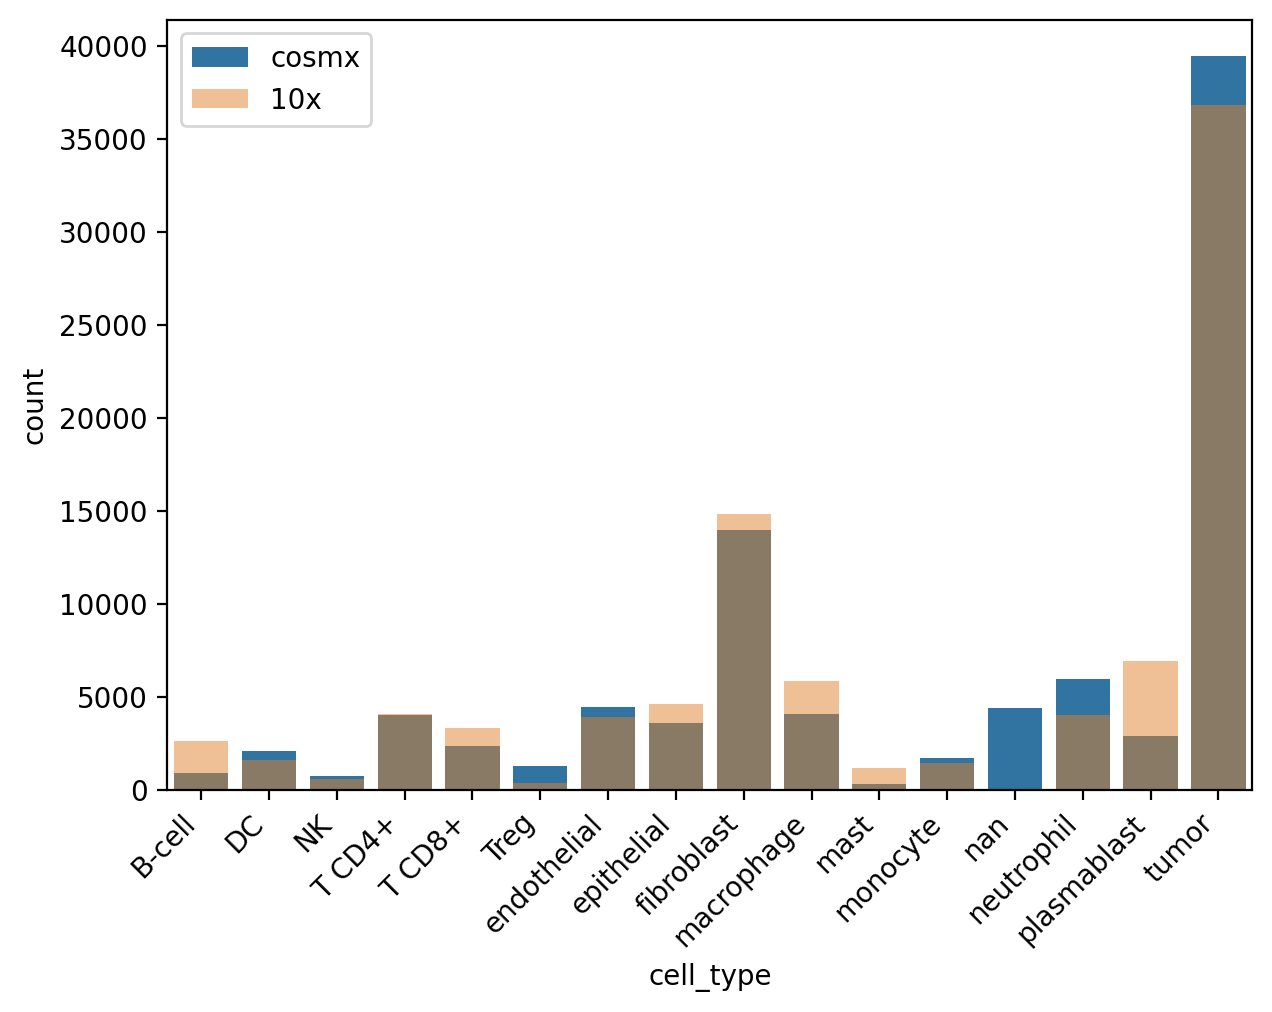

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(7,5),dpi=200)
sns.countplot(st_data.obs,x='cell_type',label='cosmx')
sns.countplot(sc_mapped.obs,x='cell_type',label='10x',alpha=0.5)
_ = ax.set_xticklabels(ax.get_xticklabels(),ha='right',rotation=45)

In [6]:
sc_mapped.obs['split'] = 'train'
splits = sc_data.obs.groupby('cell_type').cumcount().apply(lambda x: x % 5)
val_ids = splits[splits==4].index.tolist()


sc_mapped.obs.loc[sc_mapped.obs['source_sc_id'].isin(val_ids),'split'] = 'val'
sc_mapped.uns['sc_reference_to_spatial_mapping']['spatial_cols'] = np.array(['CenterX_global_px','CenterY_global_px']).astype(str)

/tmp/ipykernel_1103640/2368894823.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  splits = sc_data.obs.groupby('cell_type').cumcount().apply(lambda x: x % 5)


In [7]:
sc_mapped.write_h5ad("/work/magroup/skrieger/Syndri/data/trainsets/10x_Lung9Rep1_nsclc_integrated.h5ad")